In [15]:
import os
import glob

os.environ['YOLO_VERBOSE'] = 'False'

import numpy as np
import pandas as pd
from ultralytics import YOLO
import matplotlib.pyplot as plt

pd.options.display.float_format = '{:.3f}'.format

%matplotlib inline

In [16]:
WEIGHTS_PTH = "results/filtered_v3_margin_15_reduced_quality_box_01_dfl_01/weights/best.pt"

BASE_PTH = "/home/klymy/data/people_detection/filtered_v3_margin_15_reduced_quality"

VAL_PTH = os.path.join(BASE_PTH, "project.yaml")
HOLDOUT_PTH = os.path.join(BASE_PTH, "project_holdout.yaml")
ALGOTEST_PTH = os.path.join(BASE_PTH, "project_algotest.yaml")

VAL_IMGS_PTH = os.path.join(BASE_PTH, "images/val")
HOLDOUT_IMGS_PTH = os.path.join(BASE_PTH, "images/holdout")
ALGOTEST_IMGS_PTH = os.path.join(BASE_PTH, "images/algotest")

In [17]:
CONF_TH = 0.0
IOU_TH = 0.5

In [18]:
def print_metrics(metrics, conf_th=0, draw=True):
    data = [
        {
            "task": "box",
            "F1": metrics.box.f1[0],
            "P": metrics.box.p[0],
            "R": metrics.box.r[0],
            "MAP@50": metrics.box.map50,
        },
        {
            "task": "pose",
            "F1": metrics.pose.f1[0],
            "P": metrics.pose.p[0],
            "R": metrics.pose.r[0],
            "MAP@50": metrics.pose.map50,
        }
    ]
    print(pd.DataFrame(data))

    if not draw:
        return
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    x = np.linspace(conf_th, 1, num=len(metrics.box.f1_curve[0]), endpoint=True)
    plt.plot(x, metrics.box.f1_curve[0], label="F1")
    plt.plot(x, metrics.box.r_curve[0], label="R")
    plt.plot(x, metrics.box.p_curve[0], label="P")
    plt.grid(True)
    plt.ylim(-0.1, 1.1)
    plt.xlabel("Confidence")
    plt.legend()
    plt.title("BOX")

    plt.subplot(1, 2, 2)
    x = np.linspace(conf_th, 1, num=len(metrics.pose.f1_curve[0]), endpoint=True)
    plt.plot(x, metrics.pose.f1_curve[0], label="F1")
    plt.plot(x, metrics.pose.r_curve[0], label="R")
    plt.plot(x, metrics.pose.p_curve[0], label="P")
    plt.grid(True)
    plt.ylim(-0.1, 1.1)
    plt.xlabel("Confidence")
    plt.legend()
    plt.title("POSE");

## Default Validation

### Hold-out set

   task    F1     P     R  MAP@50
0   box 0.913 0.925 0.901   0.948
1  pose 0.931 0.940 0.923   0.972


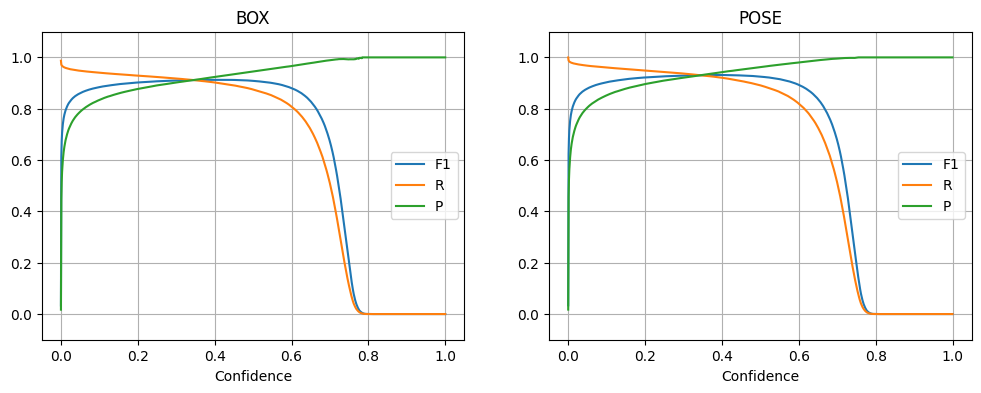

In [19]:
model = YOLO(WEIGHTS_PTH)
metrics = model.val(
    data=HOLDOUT_PTH,
    task="pose",
    device=[0],
    batch=256,
    verbose=False,
    conf=CONF_TH,
    iou=IOU_TH,
)

print_metrics(metrics, CONF_TH)

### Algotest set

   task    F1     P     R  MAP@50
0   box 0.903 0.921 0.887   0.940
1  pose 0.916 0.931 0.901   0.959


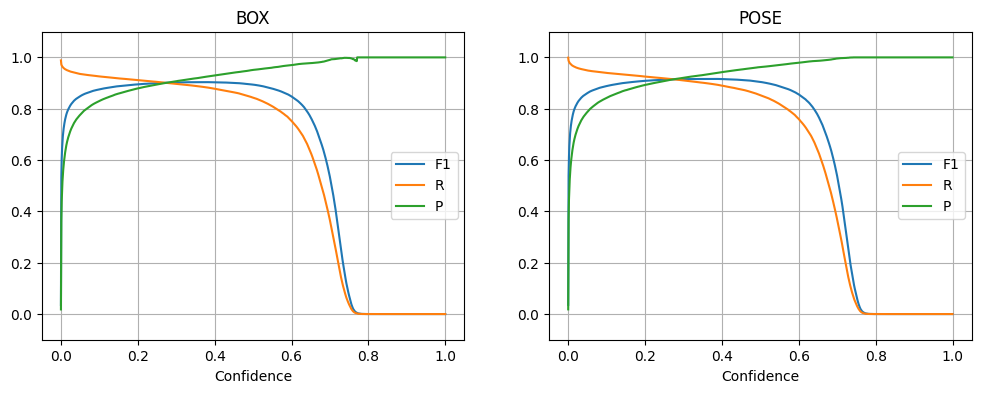

In [20]:
model = YOLO(WEIGHTS_PTH)
metrics = model.val(
    data=ALGOTEST_PTH,
    task="pose",
    device=[0],
    batch=256,
    verbose=False,
    conf=CONF_TH,
    iou=IOU_TH,
)

print_metrics(metrics, CONF_TH)

## CONF TH

In [21]:
model = YOLO(WEIGHTS_PTH)

for conf_th in np.arange(0.2, 0.41, 0.05):
    metrics = model.val(
        data=HOLDOUT_PTH,
        task="pose",
        device=[2],
        batch=128,
        verbose=False,
        conf=conf_th,
        iou=IOU_TH,
    )
    print(conf_th, ":")
    print_metrics(metrics, conf_th, draw=False)
    print(f"{'=' * 75}\n")

0.2 :
   task    F1     P     R  MAP@50
0   box 0.913 0.925 0.901   0.944
1  pose 0.931 0.940 0.923   0.962

0.25 :
   task    F1     P     R  MAP@50
0   box 0.913 0.925 0.901   0.942
1  pose 0.931 0.940 0.923   0.960

0.3 :
   task    F1     P     R  MAP@50
0   box 0.913 0.925 0.901   0.940
1  pose 0.931 0.940 0.923   0.957

0.35 :
   task    F1     P     R  MAP@50
0   box 0.913 0.925 0.901   0.937
1  pose 0.931 0.937 0.926   0.955

0.39999999999999997 :
   task    F1     P     R  MAP@50
0   box 0.913 0.924 0.902   0.933
1  pose 0.931 0.943 0.921   0.951



In [22]:
model = YOLO(WEIGHTS_PTH)

for conf_th in np.arange(0.2, 0.41, 0.05):
    metrics = model.val(
        data=ALGOTEST_PTH,
        task="pose",
        device=[2],
        batch=128,
        verbose=False,
        conf=conf_th,
        iou=IOU_TH,
    )
    print(conf_th, ":")
    print_metrics(metrics, conf_th, draw=False)
    print(f"{'=' * 75}\n")

0.2 :
   task    F1     P     R  MAP@50
0   box 0.903 0.921 0.887   0.933
1  pose 0.916 0.931 0.901   0.946

0.25 :
   task    F1     P     R  MAP@50
0   box 0.903 0.921 0.887   0.930
1  pose 0.916 0.931 0.901   0.944

0.3 :
   task    F1     P     R  MAP@50
0   box 0.903 0.921 0.887   0.928
1  pose 0.916 0.931 0.901   0.941

0.35 :
   task    F1     P     R  MAP@50
0   box 0.903 0.918 0.889   0.924
1  pose 0.916 0.931 0.901   0.937

0.39999999999999997 :
   task    F1     P     R  MAP@50
0   box 0.903 0.930 0.878   0.920
1  pose 0.915 0.942 0.890   0.932



In [23]:
TUNED_CONF_TH = 0.25

## IOU THRESHOLD

In [24]:
model = YOLO(WEIGHTS_PTH)

for iou_th in [0.45, 0.5, 0.55, 0.65]:
    metrics = model.val(
        data=HOLDOUT_PTH,
        task="pose",
        device=[2],
        batch=128,
        verbose=False,
        conf=TUNED_CONF_TH,
        iou=iou_th,
    )
    print(iou_th, ":")
    print_metrics(metrics, TUNED_CONF_TH, draw=False)
    print(f"{'=' * 75}\n")

0.45 :
   task    F1     P     R  MAP@50
0   box 0.913 0.925 0.901   0.941
1  pose 0.932 0.940 0.923   0.960



Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e5f838ca680>
Traceback (most recent call last):
  File "/home/klymy/.pyenv/versions/yolo-export/lib/python3.10/site-packages/torch/utils/data/dataloader.py", line 1477, in __del__
    self._shutdown_workers()
  File "/home/klymy/.pyenv/versions/yolo-export/lib/python3.10/site-packages/torch/utils/data/dataloader.py", line 1460, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.10/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e5f838ca680>
Traceback (most recent call last):
  File "/home/klymy/.pyenv/versions/yolo-export/lib/python3.10/site-packages/torch/utils/data/dataloader.py", line 1477, in __del__
    self._shutdown_workers()
  File "/home/klymy/.pyenv/versions/yolo-export/lib/python3.10/s

0.5 :
   task    F1     P     R  MAP@50
0   box 0.913 0.925 0.901   0.942
1  pose 0.931 0.940 0.923   0.960

0.55 :
   task    F1     P     R  MAP@50
0   box 0.913 0.925 0.901   0.942
1  pose 0.931 0.940 0.923   0.960

0.65 :
   task    F1     P     R  MAP@50
0   box 0.912 0.926 0.898   0.942
1  pose 0.930 0.941 0.919   0.960



In [25]:
model = YOLO(WEIGHTS_PTH)

for iou_th in [0.45, 0.5, 0.55, 0.65]:
    metrics = model.val(
        data=ALGOTEST_PTH,
        task="pose",
        device=[2],
        batch=128,
        verbose=False,
        conf=TUNED_CONF_TH,
        iou=iou_th,
    )
    print(iou_th, ":")
    print_metrics(metrics, TUNED_CONF_TH, draw=False)
    print(f"{'=' * 75}\n")

0.45 :
   task    F1     P     R  MAP@50
0   box 0.903 0.921 0.886   0.930
1  pose 0.916 0.931 0.902   0.944

0.5 :
   task    F1     P     R  MAP@50
0   box 0.903 0.921 0.887   0.930
1  pose 0.916 0.931 0.901   0.944

0.55 :
   task    F1     P     R  MAP@50
0   box 0.903 0.921 0.887   0.931
1  pose 0.915 0.931 0.900   0.944

0.65 :
   task    F1     P     R  MAP@50
0   box 0.902 0.924 0.882   0.931
1  pose 0.914 0.934 0.895   0.944



In [26]:
TUNED_IOU_TH = 0.55

In [27]:
import json
with open(os.path.join(WEIGHTS_PTH.replace("weights/best.pt", ""), "inference_params.json"), "w") as f:
    json.dump({
        "conf_th": TUNED_CONF_TH,
        "iou_th": TUNED_IOU_TH,
    }, f, indent=4)

TUNED_IOU_TH = 0.5

## Visuzlization

In [28]:
model = YOLO(WEIGHTS_PTH)

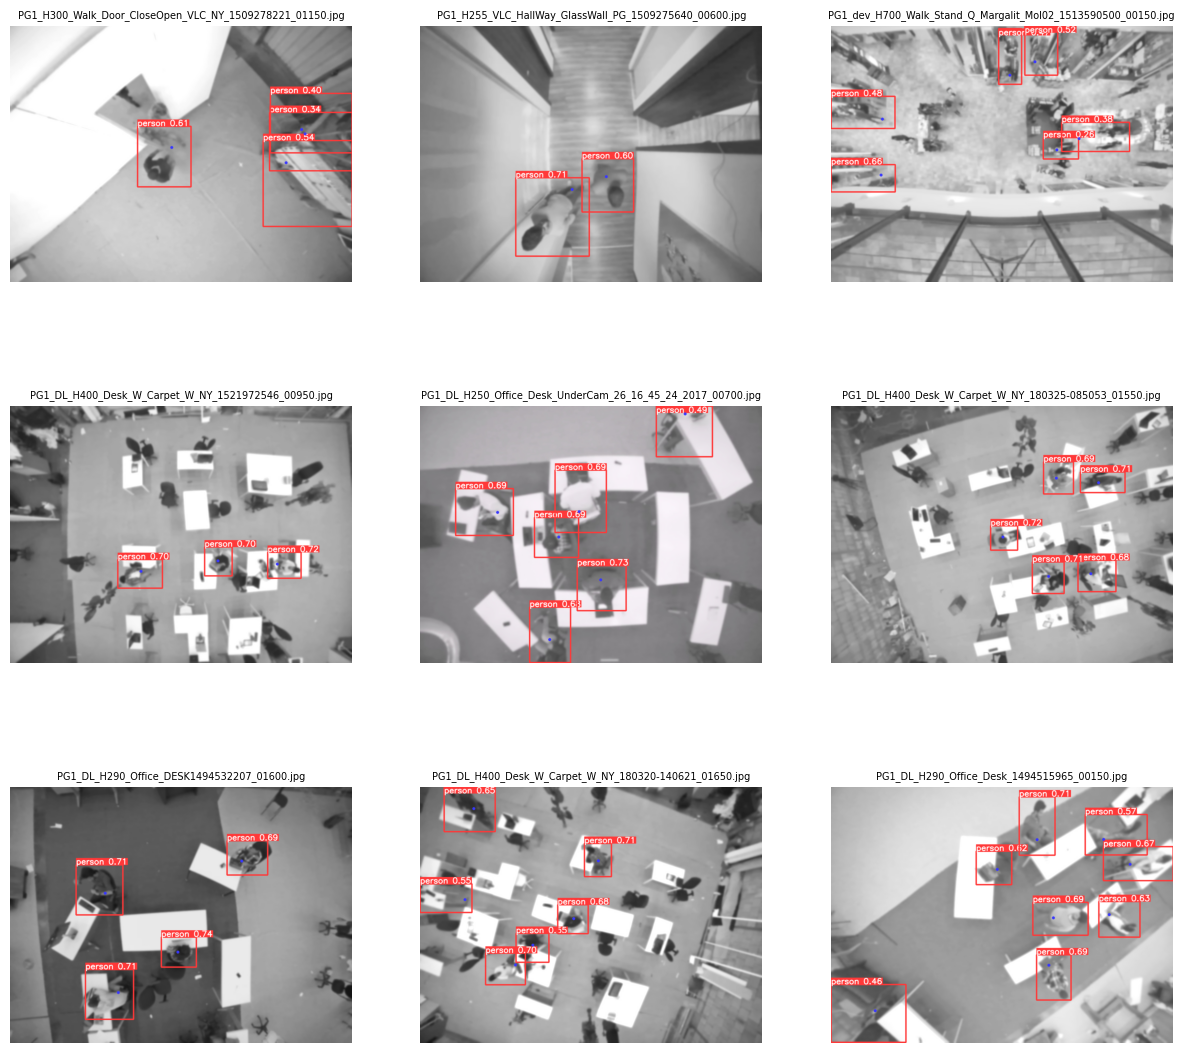

In [29]:
img_pths = glob.glob(os.path.join(VAL_IMGS_PTH, "*.jpg"))

np.random.seed(42)
np.random.shuffle(img_pths)
img_pths = img_pths[:9]

results = model(img_pths, conf=TUNED_CONF_TH, iou=TUNED_IOU_TH)

plt.figure(figsize=(15, 14))
for i, result in enumerate(results):
    plt.subplot(3, 3, i + 1)
    plt.imshow(result.plot()[:, :, ::-1])
    plt.axis('off')
    # plt.tight_layout()
    plt.title(result.path.split("/")[-1], fontsize=7)

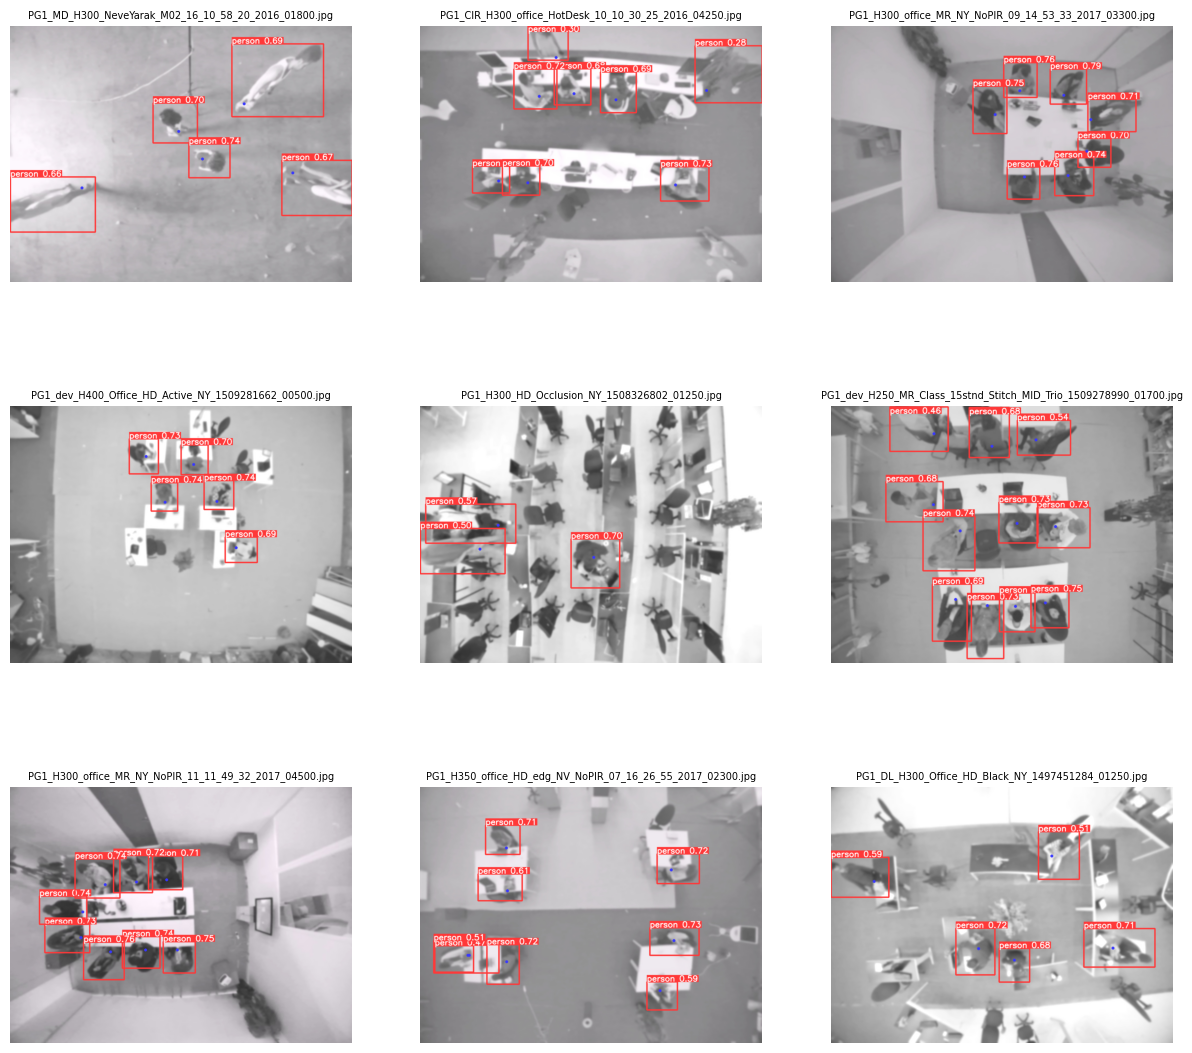

In [30]:
img_pths = glob.glob(os.path.join(HOLDOUT_IMGS_PTH, "*.jpg"))

np.random.seed(42)
np.random.shuffle(img_pths)
img_pths = img_pths[:9]

results = model(img_pths, conf=TUNED_CONF_TH, iou=TUNED_IOU_TH)

plt.figure(figsize=(15, 14))
for i, result in enumerate(results):
    plt.subplot(3, 3, i + 1)
    plt.imshow(result.plot()[:, :, ::-1])
    plt.axis('off')
    # plt.tight_layout()
    plt.title(result.path.split("/")[-1], fontsize=7)